# Sales Forecasting with Rolling-Origin Backtesting

**Business question:** a UK wholesaler needs a daily sales forecast for the **next 4 weeks** to plan staffing and stock. Which method should it use, and how far can the numbers be trusted?

**Data:** daily gross sales from the real **UCI Online Retail** transactions (Dec 2010 - 8 Dec 2011, 304 trading days). Built by `src/make_daily_series.py` with the same cleaning rules as project 05.

**What makes this project different from a typical "forecast with Prophet" notebook**

| Practice | Why it matters |
|---|---|
| **Rolling-origin backtest** (many forecast dates, never a single split) | one split can flatter or ruin a model by luck |
| Strong **baselines first** (naive, seasonal naive, trailing profile) | a model is only useful if it beats the simple thing |
| Errors reported as **WAPE, bias and 4-week total error** | a forecast can be accurate day by day and still be biased |
| **Prediction intervals** from past errors, with measured coverage | planners need a range, and the range has to be honest |
| A **pre-written limitation**: one year of data cannot teach annual seasonality | being clear about what cannot be learned from the data

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv("../data/daily_sales.csv", parse_dates=["date"]).set_index("date")
print(raw.shape, raw.index.min().date(), "->", raw.index.max().date())

(304, 2) 2010-12-01 -> 2011-12-08


## 1. Build the forecasting calendar

The business **never trades on Saturdays**, so I use a *trading-day* calendar (Mon-Fri + Sun, 6 days a week). Days when it was closed (Christmas break, bank holidays) are kept as **missing**, not zero:
they are excluded from scoring because the question here is "how much will we sell on a normal trading day", and closures are known in advance.

320 calendar trading days, 16 closed days (kept as NaN), 304 days with sales
closed days: 24 Dec, 26 Dec, 27 Dec, 28 Dec, 29 Dec, 30 Dec, 31 Dec, 02 Jan, 03 Jan, 22 Apr, 24 Apr, 25 Apr, 29 Apr, 02 May, 30 May, 29 Aug


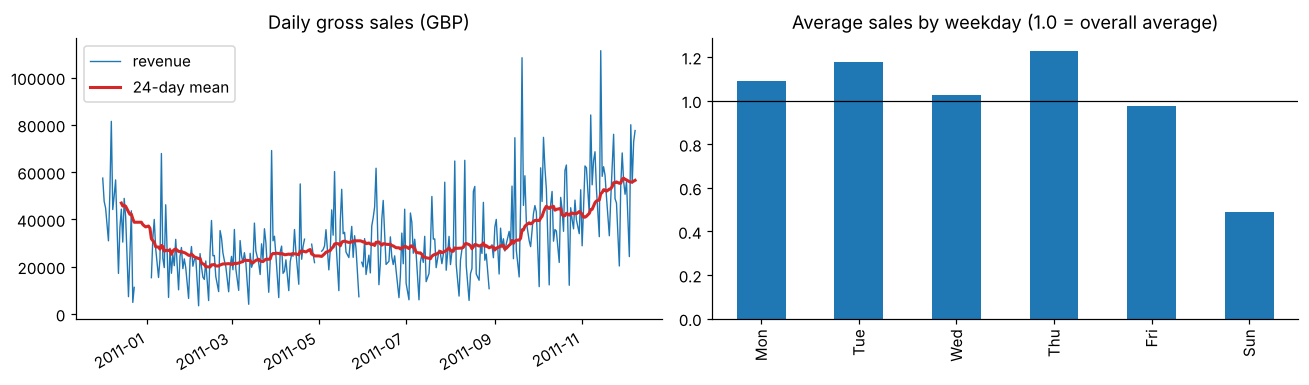

2010-12     776  |  2011-01     593  |  2011-02     508  |  2011-03     690  |  2011-04     515  |  2011-05     740  |  2011-06     738  |  2011-07     688  |  2011-08     724  |  2011-09    1028  |  2011-10    1103  |  2011-11    1452  |  2011-12     416  |  Freq: M


In [2]:
cal = pd.date_range(raw.index.min(), raw.index.max())
cal = cal[cal.dayofweek != 5]                      # no Saturdays in this business
y = raw.revenue.reindex(cal)                        # closures -> NaN
dow = pd.Series(np.where(cal.dayofweek == 6, 5, cal.dayofweek), index=cal)  # Mon0..Fri4, Sun5
print(f"{len(cal)} calendar trading days, {y.isna().sum()} closed days (kept as NaN), {y.notna().sum()} days with sales")
print("closed days:", ", ".join(d.strftime("%d %b") for d in y[y.isna()].index))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
y.plot(ax=ax[0], lw=.9); y.rolling(24, min_periods=12).mean().plot(ax=ax[0], lw=2, color="C3", label="24-day mean")
ax[0].set_title("Daily gross sales (GBP)"); ax[0].legend(); ax[0].set_xlabel("")
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sun"]
(y.groupby(dow).mean() / y.mean()).set_axis(names).plot.bar(ax=ax[1], color="C0"); ax[1].axhline(1, color="k", lw=.8)
ax[1].set_title("Average sales by weekday (1.0 = overall average)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig("../images/01_series_and_weekday.png", bbox_inches="tight"); plt.show()
m = y.groupby(y.index.to_period("M")).sum(); print((m / 1e3).round(0).astype(int).to_string().replace("\n", "  |  "))

**Reading:** two patterns matter for forecasting: a clear **weekday profile** (Thursday and Tuesday strongest, Sunday only about half a normal day) and a **strong upward drift into autumn** (Sep-Nov are the biggest months).
The first is easy to learn from the past. The second is the hard part: the data holds **only one year**, so no model can have seen a previous November.
December 2011 is incomplete, so the last forecast origins cannot reach all the way to the real peak/after-peak.

## 2. Forecast set-up (decided before looking at any scores)

* **Horizon:** 24 trading days (about 4 weeks).
* **Origins:** first forecast made after 150 trading days of history, then a new origin every 12 trading days (about every 2 weeks), as long as 24 future days exist. At each origin a model sees **only data up to that day**.
* **Scoring:** on days that had sales. **WAPE** = total absolute error / total actual sales (a scale-free % error that is not distorted by small days). **Bias** = total forecast / total actual - 1. **4-week total error** = error of the summed forecast.

## 3. Models
| Model | Idea |
|---|---|
| Naive | tomorrow = last observed day |
| Seasonal naive | same weekday last week |
| Trailing weekday mean | average of the same weekday over the last 4 weeks |
| Level x weekday profile | recent 24-day average level x weekday factors estimated over the last 12 weeks |
| ETS (Holt-Winters) | damped trend + additive 6-day seasonal cycle, refit at every origin |
| Gradient boosting | one pooled model predicting `sales / recent level` from the weekday, forecast horizon and trend features; trained **only on pairs fully inside the history** |

In [3]:
H, MIN_TRAIN, STEP = 24, 150, 12
n = len(y); origins = list(range(MIN_TRAIN, n - H + 1, STEP))
print(len(origins), "forecast origins:", y.index[origins[0] - 1].date(), "...", y.index[origins[-1] - 1].date())

def prof(hist, dw, weeks=12):
    h = hist.iloc[-6 * weeks:]; d = dw.loc[h.index]
    f = h.groupby(d).mean() / h.mean(); return f.reindex(range(6)).fillna(1.0)

def fc_naive(hist, dw, fdw): return np.repeat(hist.dropna().iloc[-1], len(fdw))
def fc_snaive(hist, dw, fdw):
    last = hist.iloc[-6:]; d = dict(zip(dw.loc[last.index], last.values))
    return np.array([d.get(k, np.nan) for k in fdw])
def fc_wkmean(hist, dw, fdw):
    h = hist.iloc[-24:]; g = h.groupby(dw.loc[h.index]).mean(); return g.reindex(fdw).fillna(h.mean()).values
def fc_levelprof(hist, dw, fdw):
    return hist.iloc[-24:].mean() * prof(hist, dw).reindex(fdw).values
def fc_ets(hist, dw, fdw):
    h = hist.copy(); h = h.fillna(h.rolling(24, min_periods=1).mean().shift(1)).ffill().bfill()
    fit = ExponentialSmoothing(h.values, trend="add", damped_trend=True, seasonal="add", seasonal_periods=6, initialization_method="estimated").fit()
    return fit.forecast(len(fdw))

def feats(hist_vals, t):
    # features known at origin t (use values strictly before t)
    v = hist_vals[:t]; lvl = np.nanmean(v[-24:]); return lvl, np.nanmean(v[-6:]) / lvl, np.nanmean(v[-72:]) / lvl
def fc_gb(hist, dw, fdw, seed=0):
    v = hist.values; t_end = len(v); dwv = dw.loc[hist.index].values; rows = []
    for o in range(72, t_end - 1):
        lvl, f6, f72 = feats(v, o)
        for hh in range(1, min(H, t_end - o) + 1):
            tgt = v[o + hh - 1]
            if not np.isnan(tgt): rows.append((f6, f72, dwv[o + hh - 1], hh, tgt / lvl))
    A = np.array(rows); Xtr, ytr = A[:, :4], np.clip(A[:, 4], 0, 4)
    mdl = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=150, min_samples_leaf=40, random_state=seed).fit(Xtr, ytr)
    lvl, f6, f72 = feats(v, t_end)
    Xf = np.array([[f6, f72, d, hh + 1] for hh, d in enumerate(fdw)])
    return lvl * mdl.predict(Xf)

MODELS = {"Naive": fc_naive, "Seasonal naive": fc_snaive, "Trailing weekday mean": fc_wkmean,
          "Level x weekday profile": fc_levelprof, "ETS (Holt-Winters)": fc_ets, "Gradient boosting": fc_gb}
recs = []
for o in origins:
    hist = y.iloc[:o]; fidx = y.index[o:o + H]; fdw = dow.loc[fidx].values
    for name, fn in MODELS.items():
        p = np.asarray(fn(hist, dow, fdw), float)
        for i, (dt, pp) in enumerate(zip(fidx, p)): recs.append((y.index[o - 1], dt, i + 1, name, pp, y.loc[dt]))
bt = pd.DataFrame(recs, columns=["origin", "date", "h", "model", "forecast", "actual"])
bt["fill"] = bt.forecast.isna(); bt["forecast"] = bt.forecast.fillna(bt.groupby(["origin", "model"]).forecast.transform("mean"))
print(len(bt), "forecasts;", int(bt.fill.sum()), "seasonal-naive gaps filled with the origin mean")

13 forecast origins: 2011-05-24 ... 2011-11-08


1872 forecasts; 4 seasonal-naive gaps filled with the origin mean


## 4. Backtest results

,WAPE_mean,WAPE_sd,bias,total_err_mean_abs,beats seasonal naive (origins)
model,,,,,
Level x weekday profile,30.9%,3.8%,-8.0%,13.3%,12/13
ETS (Holt-Winters),31.0%,5.6%,-7.4%,12.6%,12/13
Trailing weekday mean,33.6%,5.2%,-7.8%,13.4%,11/13
Gradient boosting,33.8%,7.6%,+2.8%,17.6%,10/13
Seasonal naive,39.5%,8.1%,-4.1%,13.3%,0/13
Naive,42.7%,16.7%,+8.0%,26.0%,7/13


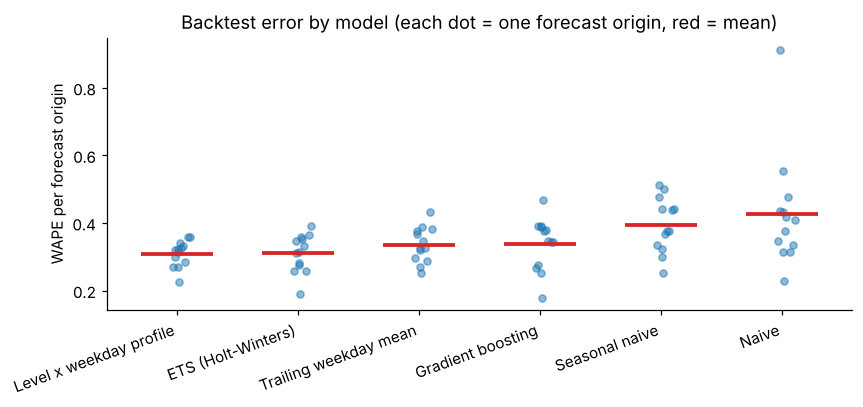

In [4]:
sc = bt.dropna(subset=["actual"]).copy(); sc["ae"] = (sc.forecast - sc.actual).abs()
def summarize(g): return pd.Series({"WAPE": g.ae.sum() / g.actual.sum(), "bias": g.forecast.sum() / g.actual.sum() - 1})
per = sc.groupby(["model", "origin"]).apply(summarize).reset_index()
tot = sc.groupby(["model", "origin"]).apply(lambda g: g.forecast.sum() / g.actual.sum() - 1).rename("total_err").reset_index()
res = per.merge(tot).groupby("model").agg(WAPE_mean=("WAPE", "mean"), WAPE_sd=("WAPE", "std"), bias=("bias", "mean"),
      total_err_mean_abs=("total_err", lambda s: s.abs().mean())).sort_values("WAPE_mean")
sn = per[per.model == "Seasonal naive"].set_index("origin").WAPE
res["beats seasonal naive (origins)"] = [f"{int((per[per.model == m].set_index('origin').WAPE < sn).sum())}/{len(origins)}" for m in res.index]
display(res.style.format({"WAPE_mean": "{:.1%}", "WAPE_sd": "{:.1%}", "bias": "{:+.1%}", "total_err_mean_abs": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(8, 3.8)); order = list(res.index)
for i, m in enumerate(order):
    v = per[per.model == m].WAPE; ax.scatter(np.full(len(v), i) + np.random.RandomState(0).uniform(-.12, .12, len(v)), v, alpha=.5, s=22, color="C0")
    ax.hlines(v.mean(), i - .3, i + .3, color="C3", lw=2.5)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order, rotation=20, ha="right"); ax.set_ylabel("WAPE per forecast origin"); ax.set_title("Backtest error by model (each dot = one forecast origin, red = mean)")
plt.tight_layout(); plt.savefig("../images/02_backtest_wape.png", bbox_inches="tight"); plt.show()

In [5]:
best = res.index[0]; base = res.loc["Seasonal naive"]; prof_row = res.loc["Level x weekday profile"]
simple_best = res.loc[["Naive", "Seasonal naive", "Trailing weekday mean", "Level x weekday profile"]].WAPE_mean.idxmin()
adv_best = res.loc[["ETS (Holt-Winters)", "Gradient boosting"]].WAPE_mean.idxmin()
gain = 1 - res.loc[best, "WAPE_mean"] / res.loc[simple_best, "WAPE_mean"]
biased_low = [m for m in res.index if res.loc[m, "bias"] < 0 and m != "Naive"]
verdict = (f"The winner improves on the best simple method by {gain:.0%}, but origin-to-origin spread is large (sd about {res.loc[best,'WAPE_sd']*100:.0f} points) and there are only {len(origins)} origins, so treat small gaps as ties."
           if gain > 0.02 else f"No advanced method clearly beats the best simple method (difference {abs(gain):.0%}); with only {len(origins)} origins the honest conclusion is a tie, and the simpler method is the safer choice.")
display(Markdown(f"**Best model on mean WAPE:** {best} ({res.loc[best,'WAPE_mean']:.1%}); best simple method: {simple_best} ({res.loc[simple_best,'WAPE_mean']:.1%}); best advanced method: {adv_best} ({res.loc[adv_best,'WAPE_mean']:.1%}). {verdict} "
    f"{len(biased_low)} of the 5 non-naive models forecast too low on average (bias {res.bias.min():+.0%} to {res.bias.max():+.0%} across all models), because sales were climbing into the autumn peak, which trailing information cannot anticipate."))

**Best model on mean WAPE:** Level x weekday profile (30.9%); best simple method: Level x weekday profile (30.9%); best advanced method: ETS (Holt-Winters) (31.0%). No advanced method clearly beats the best simple method (difference 0%); with only 13 origins the honest conclusion is a tie, and the simpler method is the safer choice. 4 of the 5 non-naive models forecast too low on average (bias -8% to +8% across all models), because sales were climbing into the autumn peak, which trailing information cannot anticipate.

### Where do the errors come from?
Splitting the origins into the "calm" period (summer) and the "ramp-up into Q4" shows whether the models fail in the same place.

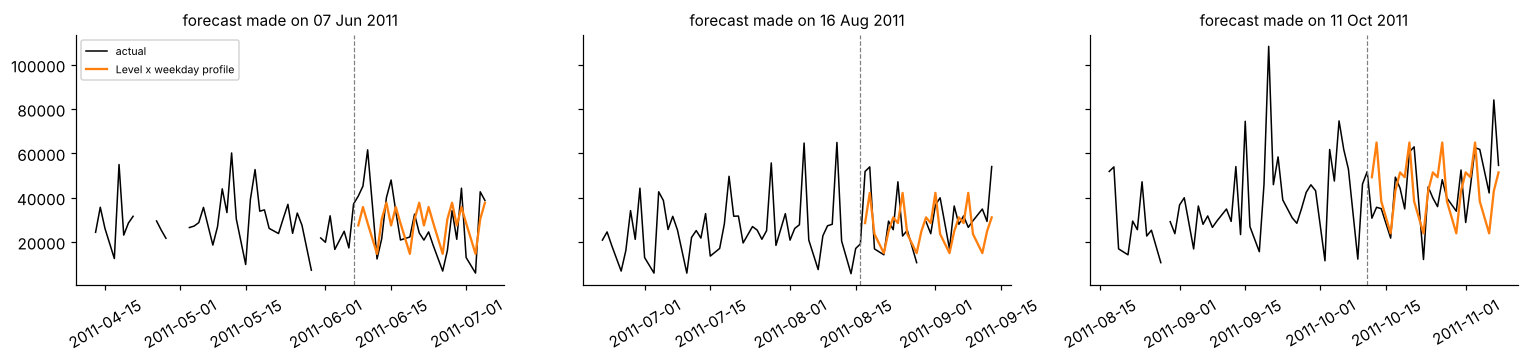

In [6]:
per["period"] = np.where(per.origin < "2011-08-01", "origin before Aug (calm)", "origin Aug onwards (Q4 ramp-up)")
tab = per.pivot_table(index="model", columns="period", values=["WAPE", "bias"], aggfunc="mean").loc[res.index]
display(tab.style.format("{:+.1%}", subset=["bias"]).format("{:.1%}", subset=["WAPE"]))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4), sharey=True)
pick = [origins[1], origins[len(origins) // 2], origins[-3]]
for ax, o in zip(axs, pick):
    s = y.iloc[max(0, o - 48):o + H]; ax.plot(s.index, s.values, color="k", lw=1, label="actual")
    for m, c in [("Level x weekday profile", "C1")] + ([(best, "C3")] if best != "Level x weekday profile" else []):
        d = bt[(bt.origin == y.index[o - 1]) & (bt.model == m)]; ax.plot(d.date, d.forecast, color=c, lw=1.5, label=m)
    ax.axvline(y.index[o - 1], color="grey", ls="--", lw=.8); ax.set_title(f"forecast made on {y.index[o-1].strftime('%d %b %Y')}", fontsize=10); ax.tick_params(axis="x", rotation=30)
axs[0].legend(fontsize=7); plt.tight_layout(); plt.savefig("../images/03_forecast_examples.png", bbox_inches="tight"); plt.show()

## 5. Prediction intervals with measured coverage
Point forecasts are not enough for planning. For the best model I build an **80% interval** from its own past errors: the 10th and 90th percentile of `actual / forecast` seen in earlier backtests.
To avoid leakage, an origin may only use past errors whose *target date is on or before that origin*. The first few origins have too little history and are skipped. The test is whether about 80% of later actuals fall inside.

6 origins, 144 daily forecasts scored | coverage of the nominal 80% interval: 81% | median width = 119% of the forecast
Q4 ramp-up    0.81


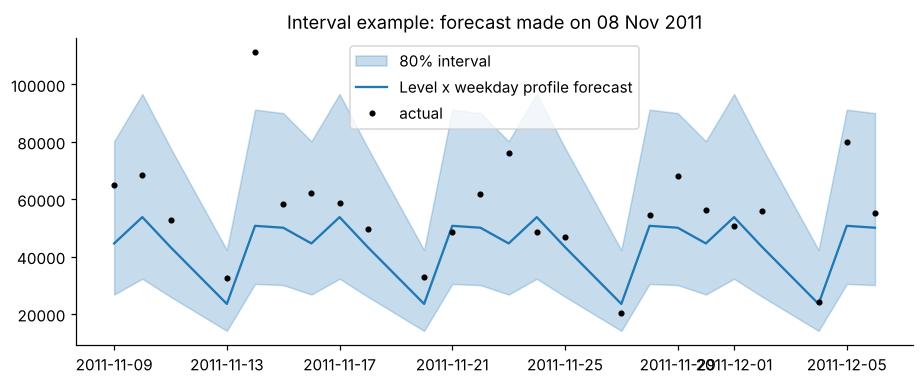

In [7]:
bb = sc[sc.model == best].copy(); bb["ratio"] = bb.actual / bb.forecast
rows = []
for o in origins[3:]:
    od = y.index[o - 1]; past = bb[bb.date <= od]
    if len(past) < 150: continue
    lo, hi = past.ratio.quantile([.10, .90]); cur = bb[bb.origin == od]
    rows.append(cur.assign(lo=cur.forecast * lo, hi=cur.forecast * hi))
iv = pd.concat(rows); iv["inside"] = (iv.actual >= iv.lo) & (iv.actual <= iv.hi)
cov = iv.inside.mean(); width = ((iv.hi - iv.lo) / iv.forecast).median()
print(f"{iv.origin.nunique()} origins, {len(iv)} daily forecasts scored | coverage of the nominal 80% interval: {cov:.0%} | median width = {width:.0%} of the forecast")
cov_by_period = iv.groupby(np.where(iv.origin < "2011-08-01", "calm period", "Q4 ramp-up")).inside.mean().round(2); print(cov_by_period.to_string())
o_last = iv.origin.max(); d = iv[iv.origin == o_last]
fig, ax = plt.subplots(figsize=(8.5, 3.6)); ax.fill_between(d.date, d.lo, d.hi, color="C0", alpha=.25, label="80% interval"); ax.plot(d.date, d.forecast, color="C0", label=f"{best} forecast"); ax.plot(d.date, d.actual, "k.", label="actual")
ax.set_title(f"Interval example: forecast made on {o_last.strftime('%d %b %Y')}"); ax.legend(); plt.tight_layout(); plt.savefig("../images/04_prediction_interval.png", bbox_inches="tight"); plt.show()

## 6. Findings, recommendation and limitations

In [8]:
s4 = (sc[sc.model == best].groupby("origin").apply(lambda g: g.forecast.sum() / g.actual.sum() - 1))
q4_bias = tab.loc[best, ("bias", "origin Aug onwards (Q4 ramp-up)")]; calm_bias = tab.loc[best, ("bias", "origin before Aug (calm)")]
wide = "wide" if width > 0.6 else "reasonably tight"
display(Markdown(f'''| # | Finding | Evidence |
|---|---|---|
| 1 | **Weekday pattern is the reliable signal** | Thursday and Tuesday are the strongest days and Sunday is only about half a normal day. The simple level x weekday profile alone reaches {res.loc["Level x weekday profile","WAPE_mean"]:.0%} WAPE vs {res.loc["Naive","WAPE_mean"]:.0%} for naive |
| 2 | **Best model (a near tie)** | {best}: mean WAPE {res.loc[best,"WAPE_mean"]:.1%} over {len(origins)} origins (best simple method {simple_best} {res.loc[simple_best,"WAPE_mean"]:.1%}; best advanced {adv_best} {res.loc[adv_best,"WAPE_mean"]:.1%}) |
| 3 | **Bias, not noise, is the main risk** | For the best model the 4-week total error averages {s4.mean():+.1%} and ranges {s4.min():+.0%} to {s4.max():+.0%} across origins. Bias is {calm_bias:+.0%} for origins before August but {q4_bias:+.0%} from August on: the autumn build-up is under-forecast |
| 4 | **Interval coverage is right, but the interval is {wide}** | The nominal 80% interval covered {cov:.0%} of later days (checked on only {iv.origin.nunique()} origins, all in the Q4 ramp-up), with a median width of {width:.0%} of the forecast: a day-level forecast is a rough guide, not a precise number |
| 5 | **Daily numbers are noisy** | Even the best model is off by roughly {res.loc[best,"WAPE_mean"]:.0%} per day; planning should lean on weekly totals and the interval |

**Recommendation:** use {simple_best if gain <= 0.05 else best} as the planning forecast, report the 80% interval next to it, add a **manual uplift for the Sep-Nov peak** based on business knowledge (promotions, last year's peak once a second year of data exists), and re-run this backtest monthly.

**Limitations:** one year of data means **annual seasonality cannot be learned or validated** (the model never saw a previous November); only {len(origins)} backtest origins, which are overlapping in target windows, so differences of a point or two are not significant;
closures/holidays are excluded rather than forecast; the series is total company sales, with no price, promotion or marketing information; two huge mistaken orders were removed by rule, which is a judgment call.'''))

| # | Finding | Evidence |
|---|---|---|
| 1 | **Weekday pattern is the reliable signal** | Thursday and Tuesday are the strongest days and Sunday is only about half a normal day. The simple level x weekday profile alone reaches 31% WAPE vs 43% for naive |
| 2 | **Best model (a near tie)** | Level x weekday profile: mean WAPE 30.9% over 13 origins (best simple method Level x weekday profile 30.9%; best advanced ETS (Holt-Winters) 31.0%) |
| 3 | **Bias, not noise, is the main risk** | For the best model the 4-week total error averages -8.0% and ranges -31% to +18% across origins. Bias is +4% for origins before August but -16% from August on: the autumn build-up is under-forecast |
| 4 | **Interval coverage is right, but the interval is wide** | The nominal 80% interval covered 81% of later days (checked on only 6 origins, all in the Q4 ramp-up), with a median width of 119% of the forecast: a day-level forecast is a rough guide, not a precise number |
| 5 | **Daily numbers are noisy** | Even the best model is off by roughly 31% per day; planning should lean on weekly totals and the interval |

**Recommendation:** use Level x weekday profile as the planning forecast, report the 80% interval next to it, add a **manual uplift for the Sep-Nov peak** based on business knowledge (promotions, last year's peak once a second year of data exists), and re-run this backtest monthly.

**Limitations:** one year of data means **annual seasonality cannot be learned or validated** (the model never saw a previous November); only 13 backtest origins, which are overlapping in target windows, so differences of a point or two are not significant;
closures/holidays are excluded rather than forecast; the series is total company sales, with no price, promotion or marketing information; two huge mistaken orders were removed by rule, which is a judgment call.